# 17 · Deep learning inference with OpenCV DNN

**Level:** Advanced / guided expert practice  
**Prerequisites:** Array shapes and channels; Train/validation/test separation; Resizing

## What you will build and learn

- Inspect NCHW preprocessing
- Run an actual offline DNN forward pass
- Understand output contracts and NMS

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Distinguish training and inference
OpenCV's DNN module loads and executes neural-network graphs. It is primarily an inference interface, not a substitute for a training framework. A graph without trained weights cannot acquire semantic recognition.

This notebook runs a real forward pass through a hand-built **ReLU → global average pooling** network. It has no learned weights and is **not an image classifier**. Its NumPy equivalent lets us verify preprocessing and inference exactly, offline. An optional branch later shows where a real ONNX classifier fits.


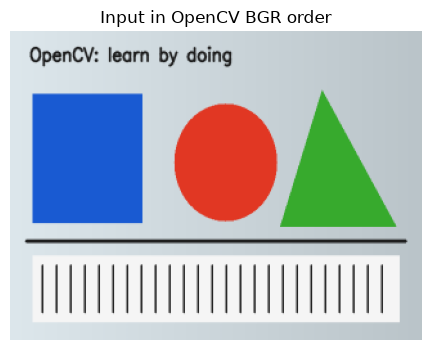

Input shape / dtype: (240, 320, 3) uint8


In [2]:
dnn_image = make_scene(width=320, height=240)
show_images([dnn_image], ['Input in OpenCV BGR order'])
print('Input shape / dtype:', dnn_image.shape, dnn_image.dtype)
dnn_dir = ROOT / 'outputs' / '17_dnn'; dnn_dir.mkdir(parents=True, exist_ok=True)


## Step 2 — Inspect the preprocessing contract
blobFromImage can resize, subtract a mean, scale, swap B/R, and return NCHW: batch, channels, height, width. These choices must match training.

Our toy contract uses 64×64 RGB and (pixel−127.5)/127.5, approximately [-1,1]. Equal means avoid mean-order ambiguity here; for unequal means, RGB/BGR ordering matters. Stretch resize changes aspect ratio and is not universally appropriate.


Blob shape/range: (1, 3, 64, 64) -0.803921639919281 0.9215686917304993


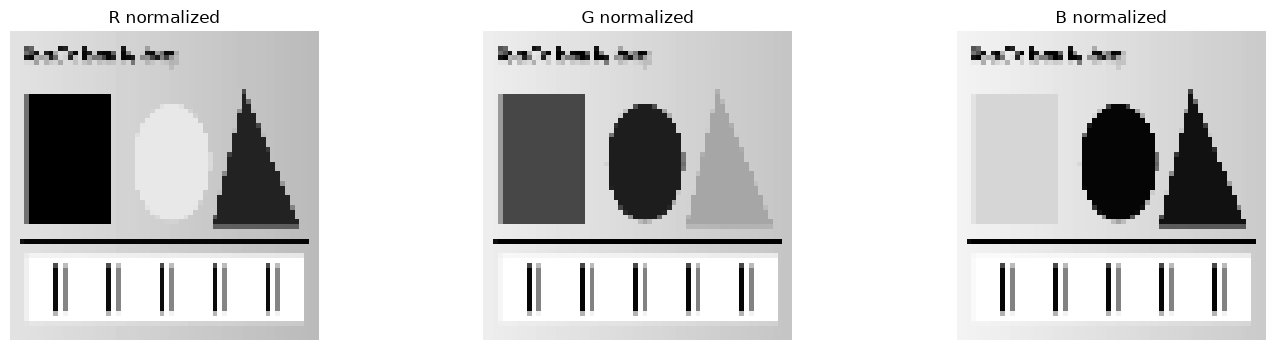

In [3]:
input_size = (64, 64)  # width, height
blob = cv2.dnn.blobFromImage(dnn_image, scalefactor=1/127.5, size=input_size,
                             mean=(127.5, 127.5, 127.5), swapRB=True, crop=False)
manual_rgb = cv2.cvtColor(cv2.resize(dnn_image, input_size), cv2.COLOR_BGR2RGB)
manual_blob = ((manual_rgb.astype(np.float32)-127.5)/127.5).transpose(2, 0, 1)[None]
assert blob.shape == (1, 3, 64, 64) and blob.dtype == np.float32
np.testing.assert_allclose(blob, manual_blob, atol=2e-7)
print('Blob shape/range:', blob.shape, float(blob.min()), float(blob.max()))
show_images([blob[0, c] for c in range(3)], ['R normalized', 'G normalized', 'B normalized'])


In [4]:
red_bgr = np.zeros((8, 8, 3), np.uint8); red_bgr[..., 2] = 255
red_rgb_blob = cv2.dnn.blobFromImage(red_bgr, 1/255, (8, 8), swapRB=True)
red_bgr_blob = cv2.dnn.blobFromImage(red_bgr, 1/255, (8, 8), swapRB=False)
print('Correct RGB channel means:', red_rgb_blob.mean(axis=(0, 2, 3)))
print('Wrong BGR channel means:  ', red_bgr_blob.mean(axis=(0, 2, 3)))
np.testing.assert_allclose(red_rgb_blob[0, :, 0, 0], [1, 0, 0])


Correct RGB channel means: [1. 0. 0.]
Wrong BGR channel means:   [0. 0. 1.]


## Step 3 — Build and execute a genuine graph
ReLU computes max(x,0); global average pooling averages each channel over space. The three outputs are **positive-channel averages**, not class scores or probabilities.

The normal path adds layers directly. A text-only Caffe graph provides the same operations for bindings without layer creation. No weights or network downloads are required.


In [5]:
def make_toy_network():
    network = cv2.dnn.Net()
    if hasattr(network, 'addLayer'):
        network.addLayer('relu', 'ReLU', cv2.CV_32F, {})
        network.connect('', 'relu')
        network.addLayer('positive_channel_mean', 'Pooling', cv2.CV_32F,
                         {'pool': 'AVE', 'global_pooling': True})
        network.connect('relu', 'positive_channel_mean')
    else:
        graph = """name: "toy_relu_average"
input: "data"
input_shape { dim: 1 dim: 3 dim: 64 dim: 64 }
layer { name: "relu" type: "ReLU" bottom: "data" top: "relu" }
layer { name: "positive_channel_mean" type: "Pooling" bottom: "relu" top: "means"
        pooling_param { pool: AVE global_pooling: true } }
"""
        graph_path = dnn_dir / 'toy_network.prototxt'
        graph_path.write_text(graph, encoding='utf-8')
        network = cv2.dnn.readNetFromCaffe(str(graph_path))
    network.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
    network.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
    return network

net = make_toy_network()
net.setInput(blob)
output = net.forward()
expected_output = np.maximum(blob, 0).mean(axis=(2, 3), keepdims=True)
print('Layers:', net.getLayerNames())
print('Output shape:', output.shape)
print('DNN / NumPy:', output.ravel(), expected_output.ravel())
np.testing.assert_allclose(output.reshape(1, 3), expected_output.reshape(1, 3), atol=2e-5)
print('Actual DNN inference matches an independent NumPy reference.')


Layers: ('relu', 'positive_channel_mean')
Output shape: (1, 3, 1, 1)
DNN / NumPy: [0.51580536 0.5234851  0.59698504] [0.5158165  0.52349883 0.5969919 ]
Actual DNN inference matches an independent NumPy reference.


Batch rows = scene, zeros, ones:
 [[0.51580536 0.5234851  0.59698504]
 [0.         0.         0.        ]
 [1.         1.         1.        ]]


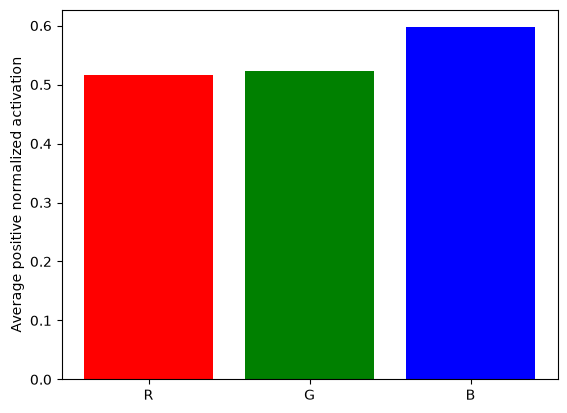

In [6]:
batch = np.concatenate([blob, np.zeros_like(blob), np.ones_like(blob)], axis=0)
net.setInput(batch)
batch_output = net.forward().reshape(3, 3)
np.testing.assert_allclose(batch_output, np.maximum(batch, 0).mean(axis=(2, 3)), atol=2e-5)
print('Batch rows = scene, zeros, ones:\n', batch_output)
plt.bar(['R', 'G', 'B'], output.ravel(), color=['red', 'green', 'blue'])
plt.ylabel('Average positive normalized activation'); plt.show()


Batches can improve throughput while increasing memory and latency. A particular graph may require fixed shapes. This small graph accepts different batch sizes; do not assume the same for a downloaded model.


In [7]:
from time import perf_counter
net.setInput(blob); net.forward()  # warm up
timings_ms = []
for _ in range(15):
    start = perf_counter()
    net.setInput(blob); net.forward()
    timings_ms.append((perf_counter()-start)*1000)
print('Toy CPU latency median / 90th percentile (ms):', np.percentile(timings_ms, [50, 90]))
print('Timing includes setInput + forward, excludes capture, preprocessing, and plotting.')


Toy CPU latency median / 90th percentile (ms): [0.0500998  0.45992001]
Timing includes setInput + forward, excludes capture, preprocessing, and plotting.


## Step 4 — Interpret outputs only with their model contract
A single-label classifier may output logits. Softmax normalizes them with exp(zᵢ)/sum(exp(zⱼ)); subtracting the maximum prevents overflow. Normalized values are not automatically calibrated confidence.

Do not softmax our channel means and call them predictions. Do not apply softmax again to probabilities. Multilabel networks often use independent sigmoids instead.


In [8]:
def stable_softmax(logits, axis=-1):
    logits = np.asarray(logits, dtype=np.float64)
    centered = logits-logits.max(axis=axis, keepdims=True)
    exponentials = np.exp(centered)
    return exponentials/exponentials.sum(axis=axis, keepdims=True)

illustrative_logits = np.array([[1001., 1002., 999.]])  # invented arithmetic, not model predictions
illustrative_probabilities = stable_softmax(illustrative_logits)
print('Arithmetic-only example:', illustrative_probabilities)
np.testing.assert_allclose(illustrative_probabilities.sum(axis=1), 1)
np.testing.assert_allclose(stable_softmax(illustrative_logits+5000), illustrative_probabilities)


Arithmetic-only example: [[0.25949646 0.70538451 0.03511903]]


Detectors have different contracts: boxes, scores, classes, sometimes masks. Coordinates may be normalized, xyxy, centre-width-height, or xywh. Decode the specific architecture first. The following boxes are explicitly invented to practice postprocessing.


## Step 5 — Non-maximum suppression
NMS retains high-score boxes and suppresses overlapping lower-score boxes. IoU is intersection area divided by union area. OpenCV NMSBoxes expects [x,y,width,height]. Apply NMS per class to avoid suppressing distinct categories.


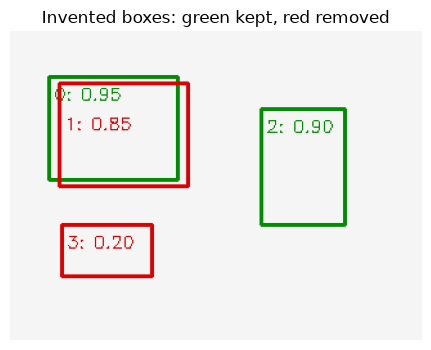

In [9]:
boxes = [[30, 35, 100, 80], [38, 40, 100, 80], [195, 60, 65, 90], [40, 150, 70, 40]]
scores = [0.95, 0.85, 0.90, 0.20]
classes = [0, 0, 1, 0]
def class_aware_nms(boxes, scores, classes, score_threshold=0.4, iou_threshold=0.4):
    kept = []
    for class_id in sorted(set(classes)):
        members = [i for i, label in enumerate(classes) if label == class_id]
        local = cv2.dnn.NMSBoxes([boxes[i] for i in members], [scores[i] for i in members],
                                 score_threshold, iou_threshold)
        kept.extend(members[int(i)] for i in np.asarray(local).reshape(-1))
    return sorted(kept)

kept = class_aware_nms(boxes, scores, classes)
assert kept == [0, 2]
canvas = np.full((240, 320, 3), 245, np.uint8)
for i, (x, y, bw, bh) in enumerate(boxes):
    color = (0, 140, 0) if i in kept else (0, 0, 220)
    cv2.rectangle(canvas, (x, y), (x+bw, y+bh), color, 2)
    label_y = y+18+(18 if i == 1 else 0)  # separate overlapping boxes' labels
    cv2.putText(canvas, f'{i}: {scores[i]:.2f}', (x+4, label_y), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)
show_images([canvas], ['Invented boxes: green kept, red removed'])


In [10]:
def box_iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    intersection = max(0, min(ax+aw, bx+bw)-max(ax, bx))*max(0, min(ay+ah, by+bh)-max(ay, by))
    union = aw*ah+bw*bh-intersection
    return intersection/union if union > 0 else 0.0

print('First two boxes IoU:', box_iou(boxes[0], boxes[1]))
for threshold in [0.1, 0.4, 0.8]:
    print('IoU threshold', threshold, 'keeps', class_aware_nms(boxes, scores, classes, iou_threshold=threshold))


First two boxes IoU: 0.7582417582417582
IoU threshold 0.1 keeps [0, 2]
IoU threshold 0.4 keeps [0, 2]
IoU threshold 0.8 keeps [0, 1, 2]


## Step 6 — Optional real ONNX classification
The default notebook completes offline. To enable this branch, supply a trusted classification ONNX model, license/model card, ordered labels, shape, channel order, normalization, resize policy, and output description.

This sample supports only one RGB/BGR NCHW input, stretch resize, and a [1,number_of_classes] logits/probability output. Fill every contract field from the model documentation; incompatible architectures need a different decoder.


In [11]:
RUN_ONNX_CLASSIFIER = False
MODEL_PATH = ROOT / 'models' / 'personal' / 'your_classifier.onnx'
LABELS_PATH = ROOT / 'models' / 'personal' / 'your_labels.txt'
MODEL_SIZE = None    # verified (width, height)
MODEL_RGB = None     # True for RGB, False for BGR
MODEL_MEAN = None    # three channel means in 0..1 units
MODEL_STD = None     # three positive channel standard deviations
MODEL_OUTPUT = None # 'logits' or 'probabilities'
MODEL_RESIZE = None # sample supports only 'stretch'

if RUN_ONNX_CLASSIFIER:
    assert MODEL_PATH.is_file() and LABELS_PATH.is_file(), 'Provide model and labels.'
    assert MODEL_SIZE is not None and MODEL_RGB is not None
    assert MODEL_MEAN is not None and MODEL_STD is not None
    assert MODEL_OUTPUT in ('logits', 'probabilities') and MODEL_RESIZE == 'stretch'
    mean = np.asarray(MODEL_MEAN, np.float32).reshape(1, 1, 3)
    std = np.asarray(MODEL_STD, np.float32).reshape(1, 1, 3)
    assert np.all(std > 0)
    resized = cv2.resize(dnn_image, tuple(MODEL_SIZE))
    if MODEL_RGB:
        resized = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    normalized = (resized.astype(np.float32)/255.0-mean)/std
    model_blob = np.ascontiguousarray(normalized.transpose(2, 0, 1)[None])
    labels = LABELS_PATH.read_text(encoding='utf-8').splitlines()
    classifier = cv2.dnn.readNetFromONNX(str(MODEL_PATH))
    classifier.setInput(model_blob)
    raw_scores = classifier.forward()
    assert raw_scores.shape == (1, len(labels)), 'Output decoder mismatch.'
    assert np.isfinite(raw_scores).all()
    probabilities = stable_softmax(raw_scores)[0] if MODEL_OUTPUT == 'logits' else raw_scores[0]
    assert (probabilities >= 0).all() and np.isclose(probabilities.sum(), 1, atol=1e-3)
    for index in np.argsort(probabilities)[-5:][::-1]:
        print(labels[index], float(probabilities[index]))
else:
    print('Optional ONNX classifier disabled. Actual toy DNN inference already ran above.')


Optional ONNX classifier disabled. Actual toy DNN inference already ran above.


### Practice
1. Predict the toy output for an all-negative blob, then execute.
2. Move a fixed-size colored patch across an input. Explain global pooling's response.
3. Put the second overlapping box in another class. Should it survive?
4. List the preprocessing assumptions you must verify before integrating a learned model.


In [12]:
negative_input = -np.ones((1, 3, 64, 64), dtype=np.float32)
net.setInput(negative_input)
negative_output = net.forward()
print('All-negative input output:', negative_output.ravel())


All-negative input output: [0. 0. 0.]


### Worked solutions
ReLU removes negative activations. Global pooling discards spatial position, so different spatial arrangements can yield identical outputs. This is another reason the untrained toy graph cannot recognize semantic content.


In [13]:
np.testing.assert_allclose(negative_output, 0, atol=1e-7)
patch_a = np.zeros((1, 3, 64, 64), np.float32); patch_a[0, 0, 5:15, 5:15] = 1
patch_b = np.zeros_like(patch_a); patch_b[0, 0, 35:45, 40:50] = 1
net.setInput(patch_a); result_a = net.forward().copy()
net.setInput(patch_b); result_b = net.forward().copy()
np.testing.assert_allclose(result_a, result_b, atol=1e-7)
print('Translated patch outputs:', result_a.ravel())
assert class_aware_nms(boxes, scores, [0, 1, 1, 0]) == [0, 1, 2]
print('Different classes preserve both overlapping boxes.')


Translated patch outputs: [0.02441406 0.         0.        ]
Different classes preserve both overlapping boxes.


### References
- [OpenCV DNN API](https://docs.opencv.org/4.x/d6/d0f/group__dnn.html)
- [OpenCV Net graph/inference API](https://docs.opencv.org/4.x/db/d30/classcv_1_1dnn_1_1Net.html)
- [OpenCV classification sample](https://github.com/opencv/opencv/blob/4.x/samples/dnn/classification.py)

For learned recognition, verify preprocessing against the training framework and compare outputs on known images before evaluating a held-out dataset. Never substitute invented detections for a failed model run.
